# 🔰 Beginner-Friendly Cybersecurity Data Analysis
### *Exploratory Data Analysis (EDA) on 3.96 Million Network Packets*

Welcome! This notebook is designed to be **simple, clear, and easy to understand**. 
There are **no complicated classes, no database setups, and no confusing advanced code**.

Just standard **Pandas** and **Matplotlib** to answer simple questions:
1. What does the data look like?
2. Are there missing or corrupted values?
3. What protocols are being used?
4. How large are the packets?
5. When did the cyber attack happen?
6. Who was attacking whom?
7. How can we detect the attacks using simple Python rules?


### 📦 Step 1: Load the Dataset
We load the dataset using standard `pandas.read_csv()`. It has **3,962,784 packets** and loads in just about 3 seconds.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Path to the dataset CSV file
import os
csv_file = "data/original/Cap_1_10VM_1Apache/L1_Cap_202209051617.csv" if os.path.exists("data/original/Cap_1_10VM_1Apache/L1_Cap_202209051617.csv") else "../data/original/Cap_1_10VM_1Apache/L1_Cap_202209051617.csv"

# Load the file into a pandas DataFrame (just 1 line of code!)
print("Loading data... please wait ~3 seconds...")
df = pd.read_csv(csv_file, low_memory=False)

print(f"Done! Loaded {len(df):,} total packets.")


Loading data... please wait ~3 seconds...


Done! Loaded 3,962,784 total packets.


### 🔍 Step 2: Look at the First Few Rows & Check for Missing Data
Let's see what columns we have and if there are any missing (NaN) values.


In [2]:
# 1. View the first 5 rows
print("--- FIRST 5 PACKETS ---")
display(df.head())

# 2. Check for missing values in each column
print("\n--- MISSING VALUES ---")
print(df.isna().sum())


--- FIRST 5 PACKETS ---


,No.,Time,Source,Destination,Protocol,Length,Time to Live,Info,Source_Known,Destination_Known
0,1,0.000000,172.18.0.2,172.16.49.2,DNS,76,64.0,Standard query 0x5002 A ports.ubuntu.com,1,0
1,2,0.183308,172.16.49.2,172.18.0.2,DNS,108,127.0,Standard query response 0x5002 A ports.ubuntu....,0,1
2,3,0.184243,172.18.0.2,185.125.190.36,TCP,74,64.0,51742 > 80 [SYN] Seq=0 Win=64240 Len=0 MSS=1...,1,0
3,4,0.310443,185.125.190.36,172.18.0.2,TCP,58,127.0,"80 > 51742 [SYN, ACK] Seq=0 Ack=1 Win=64240 ...",0,1
4,5,0.310686,172.18.0.2,185.125.190.36,TCP,54,64.0,51742 > 80 [ACK] Seq=1 Ack=1 Win=64240 Len=0,1,0



--- MISSING VALUES ---
No.                    0
Time                   0
Source                 0
Destination            0
Protocol               0
Length                 0
Time to Live         789
Info                   0
Source_Known           0
Destination_Known      0
dtype: int64


### 🌐 Step 3: What Protocols Are Being Used?
Let's count how many packets belong to TCP, ARP, ICMP, etc., and plot a simple bar chart.


Protocol
TCP         3953715
FTP            3792
SSHv2          3032
HTTP           1090
ARP             784
ICMP            200
DNS             149
FTP-DATA          6
UDP               6
ICMPv6            5
SSHv1             4
SSH               1
Name: count, dtype: int64


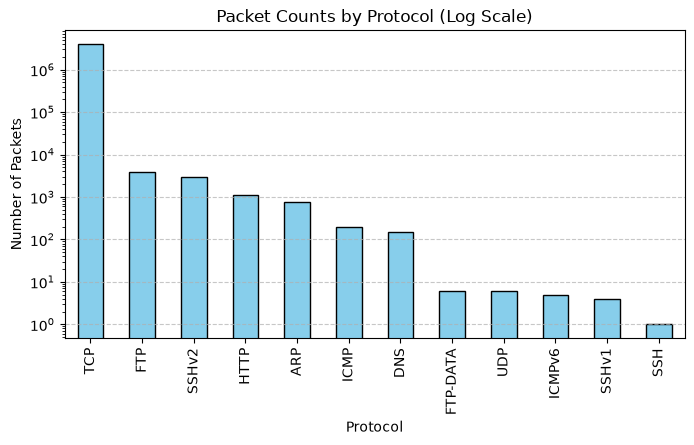

In [3]:
# Count how many packets belong to each protocol
protocol_counts = df['Protocol'].value_counts()
print(protocol_counts)

# Draw a simple bar chart
plt.figure(figsize=(8, 4))
protocol_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Packet Counts by Protocol (Log Scale)")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")
plt.yscale('log')  # We use log scale because TCP is in the millions while others are in the hundreds
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


### 📏 Step 4: How Big Are the Packets? (Finding the 174-byte Clue)
Let's inspect the `Length` column (packet size in bytes). 
Notice something strange: the 25%, 50% (median), and 75% are **all exactly 174 bytes**!


count    3.962784e+06
mean     2.165352e+02
std      1.139868e+03
min      4.200000e+01
25%      1.740000e+02
50%      1.740000e+02
75%      1.740000e+02
max      6.429300e+04
Name: Length, dtype: float64


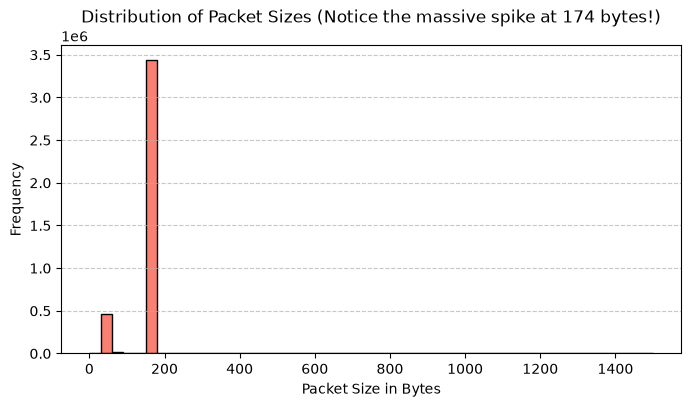

In [4]:
# Summary statistics for packet lengths
print(df['Length'].describe())

# Histogram of packet sizes between 0 and 1500 bytes
plt.figure(figsize=(8, 4))
plt.hist(df['Length'], bins=50, range=(0, 1500), color='salmon', edgecolor='black')
plt.title("Distribution of Packet Sizes (Notice the massive spike at 174 bytes!)")
plt.xlabel("Packet Size in Bytes")
plt.ylabel("Frequency")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


### ⏰ Step 5: When Did the Attack Happen? (Traffic Over Time)
The capture lasted about 24 hours (84,714 seconds). Let's plot traffic across the entire timeline to see when the attack started.


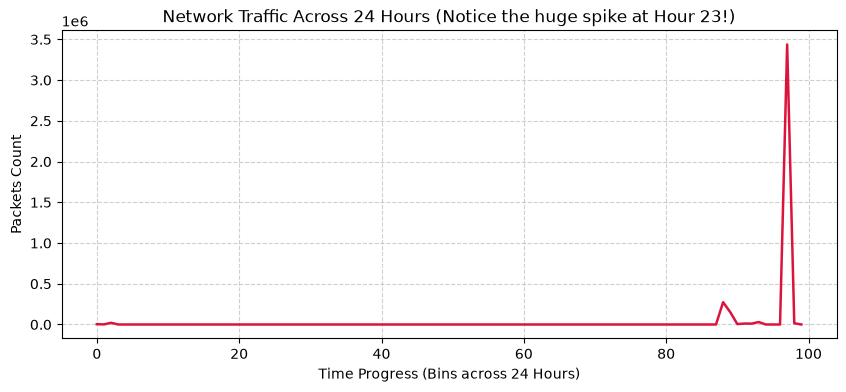

In [5]:
# Convert seconds to hours for easier reading
df['Time_Hours'] = df['Time'] / 3600

# Group the 24 hours into 100 simple time slices and count packets in each slice
time_slices = pd.cut(df['Time_Hours'], bins=100)
traffic_timeline = df.groupby(time_slices, observed=False).size()

# Plot the timeline
plt.figure(figsize=(10, 4))
plt.plot(range(len(traffic_timeline)), traffic_timeline.values, color='crimson', linewidth=1.8)
plt.title("Network Traffic Across 24 Hours (Notice the huge spike at Hour 23!)")
plt.xlabel("Time Progress (Bins across 24 Hours)")
plt.ylabel("Packets Count")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


### 🎯 Step 6: Who is Attacking Whom? (Top IPs)
Let's see which Destination IP received the most traffic, and which Source IPs sent the most traffic.


In [6]:
print("--- TOP 5 TARGET (DESTINATION) IPs ---")
print(df['Destination'].value_counts().head(5))

print("\n--- TOP 5 SENDER (SOURCE) IPs ---")
print(df['Source'].value_counts().head(5))


--- TOP 5 TARGET (DESTINATION) IPs ---


Destination
172.17.0.2        3454398
172.18.0.2         216430
172.18.0.6         203223
185.125.190.39      26002
185.125.190.36      17051
Name: count, dtype: int64

--- TOP 5 SENDER (SOURCE) IPs ---


Source
172.18.0.6        218152
172.18.0.2        217152
185.125.190.39     29787
185.125.190.36     18777
172.18.0.11        11256
Name: count, dtype: int64


### 🛡️ Step 7: Simple Attack Detection Rules
We can detect the attacks with just simple Pandas filtering rules!
1. **DDoS SYN Flood:** Over 3.4 million identical 174-byte packets targeting `172.17.0.2`.
2. **Port Scan Rejections:** ICMP error packets generated when someone scans closed ports.


In [7]:
# Rule 1: Flag all 174-byte packets attacking the web server (172.17.0.2)
ddos_packets = df[(df['Length'] == 174) & (df['Destination'] == '172.17.0.2')]

print(f"🚨 Detected DDoS Attack Packets: {len(ddos_packets):,}")
print(f"Percentage of Total Traffic: {len(ddos_packets) / len(df) * 100:.2f}%")

# Rule 2: Flag ICMP Error responses from closed ports
port_scan_packets = df[df['Protocol'] == 'ICMP']
print(f"🚨 Detected Port Scan Error Packets: {len(port_scan_packets):,}")


🚨 Detected DDoS Attack Packets: 3,436,938
Percentage of Total Traffic: 86.73%


🚨 Detected Port Scan Error Packets: 200
